# Random forest: stock volatility

Part of the ML Portfolio Model Zoo. Educational purposes only.

Given a stock's beta, debt-to-equity ratio, market cap and sector, predict its 30-day annualised volatility with a random forest, and compare it with a plain linear regression. The data is **synthetic**, with threshold and interaction effects built in.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

# Everything here reuses train.py, so the notebook and the site always use the same pipeline.

## Data

In [2]:
data = make_data()
print(data.shape)
data.head()

(4000, 5)


,beta,debt_to_equity,market_cap_bn,sector,target
0,1.14,1.1,157.0,healthcare,17.10
1,0.53,1.1,4.0,healthcare,16.96
2,1.34,2.4,53.0,technology,27.27
3,1.42,0.7,22.0,energy,31.69
4,0.20,0.4,75.0,banks,8.19


In [3]:
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
beta,4000.0,NaN,NaN,NaN,0.998178,0.435195,0.2,0.69,1.0,1.29,2.43
debt_to_equity,4000.0,NaN,NaN,NaN,1.0942,0.757063,0.0,0.5,0.9,1.5,4.0
market_cap_bn,4000.0,NaN,NaN,NaN,70.77475,87.84226,1.0,19.0,39.0,83.25,500.0
sector,4000,5,technology,1116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target,4000.0,NaN,NaN,NaN,19.930278,6.832121,4.0,15.33,19.565,24.33,46.25


## Train and evaluate

`train_and_evaluate()` fits the scikit-learn pipeline, scores it on a held-out split, exports it to ONNX and asserts that onnxruntime reproduces scikit-learn's predictions.

In [4]:
result = train_and_evaluate()
print(f"forest R² {result.metrics['r2']:.3f}   RMSE {result.metrics['rmse']:.2f}")
print(f"linear baseline R² {result.metrics['linear_baseline_r2']:.3f}   RMSE {result.metrics['linear_baseline_rmse']:.2f}")
print(f"ONNX vs sklearn max abs diff: {result.metrics['onnx_max_abs_diff']:.1e}")

forest R² 0.854   RMSE 2.57
linear baseline R² 0.800   RMSE 3.01
ONNX vs sklearn max abs diff: 4.0e-06


## Charts

The same charts the site shows, written to a temporary folder.

Predicted against actual volatility on held-out stocks.


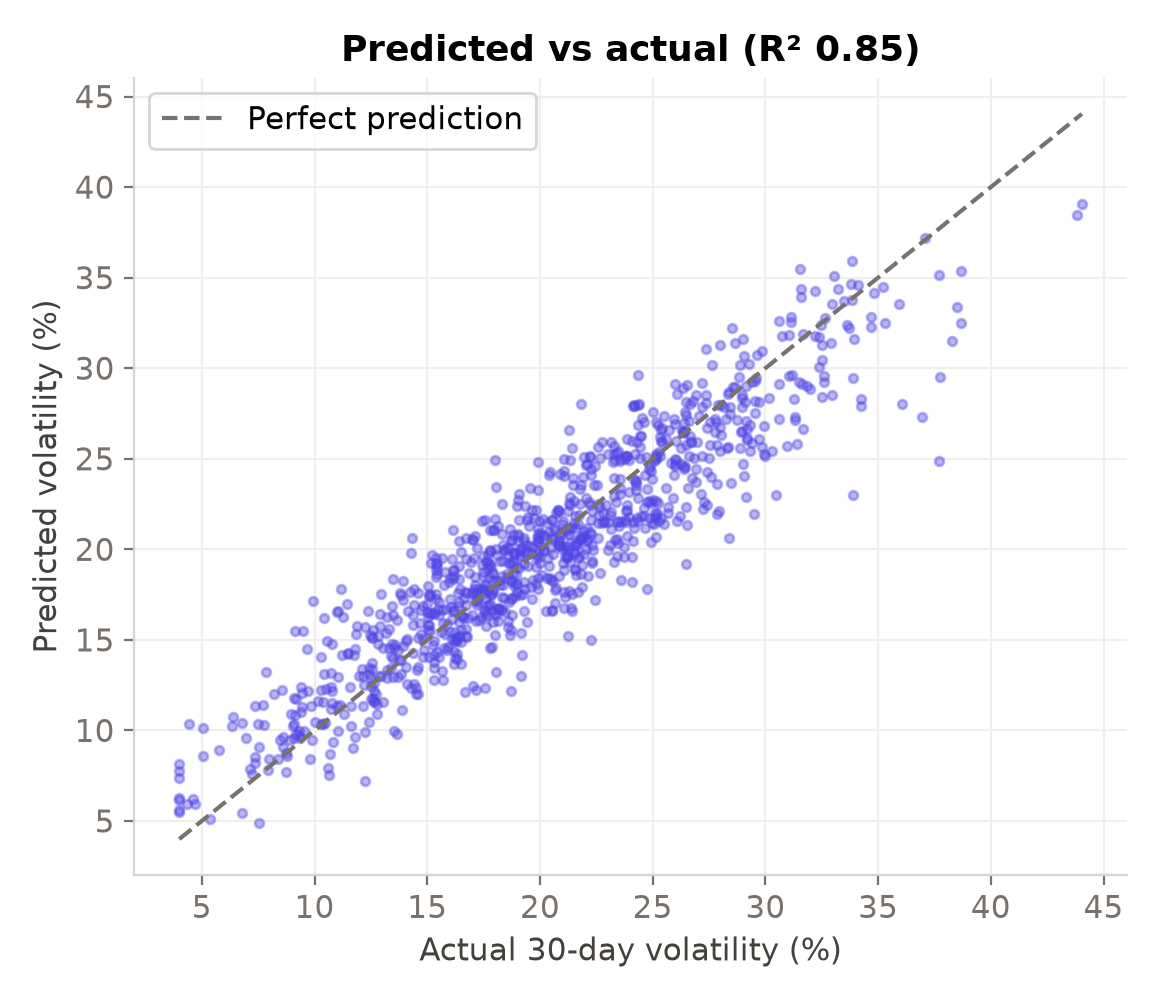

Which inputs the forest relies on most to predict volatility.


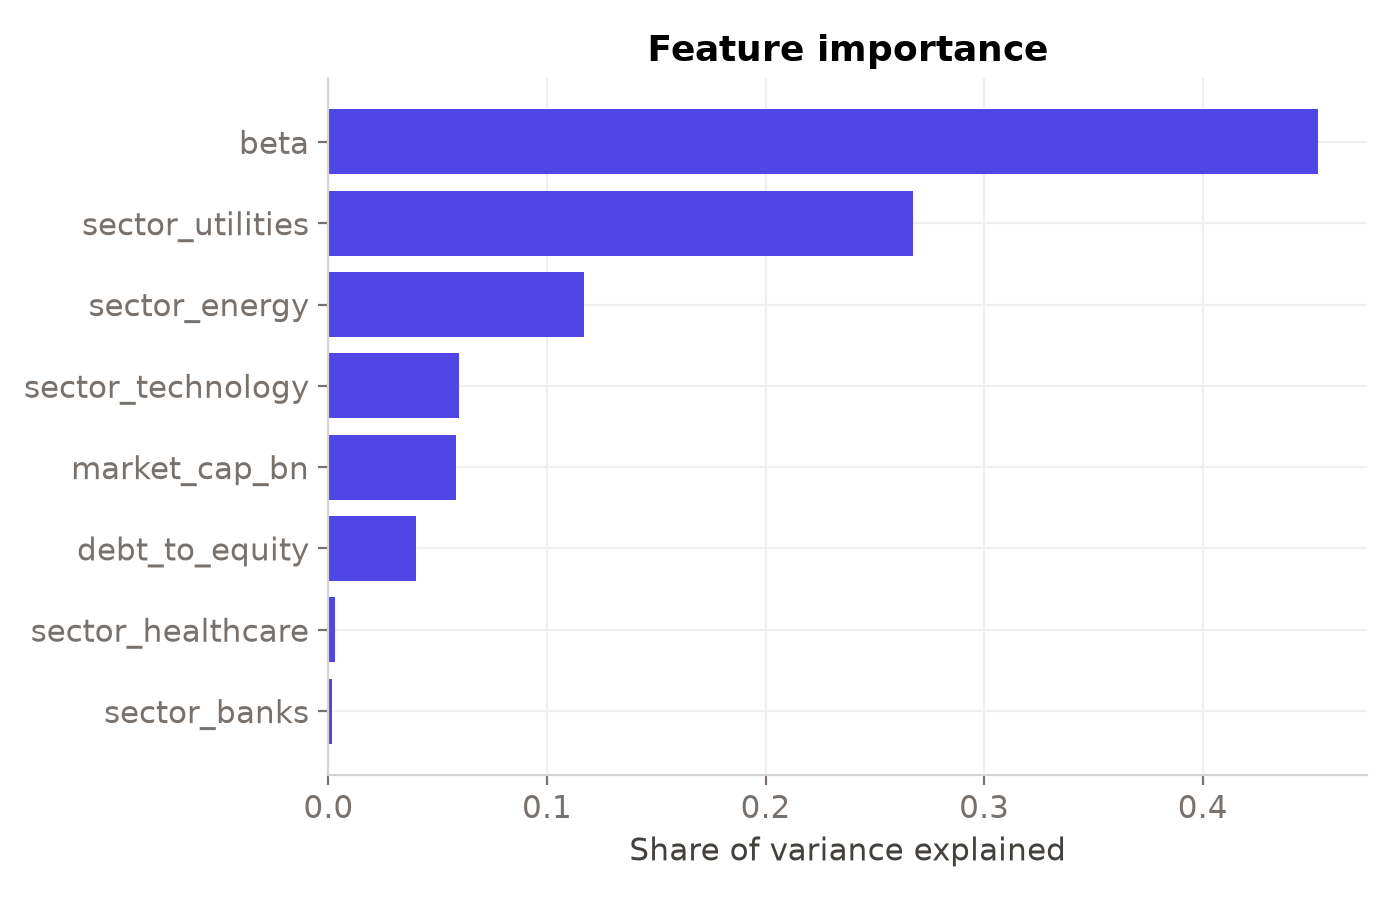

Same data, same inputs: the forest captures effects a straight line misses.


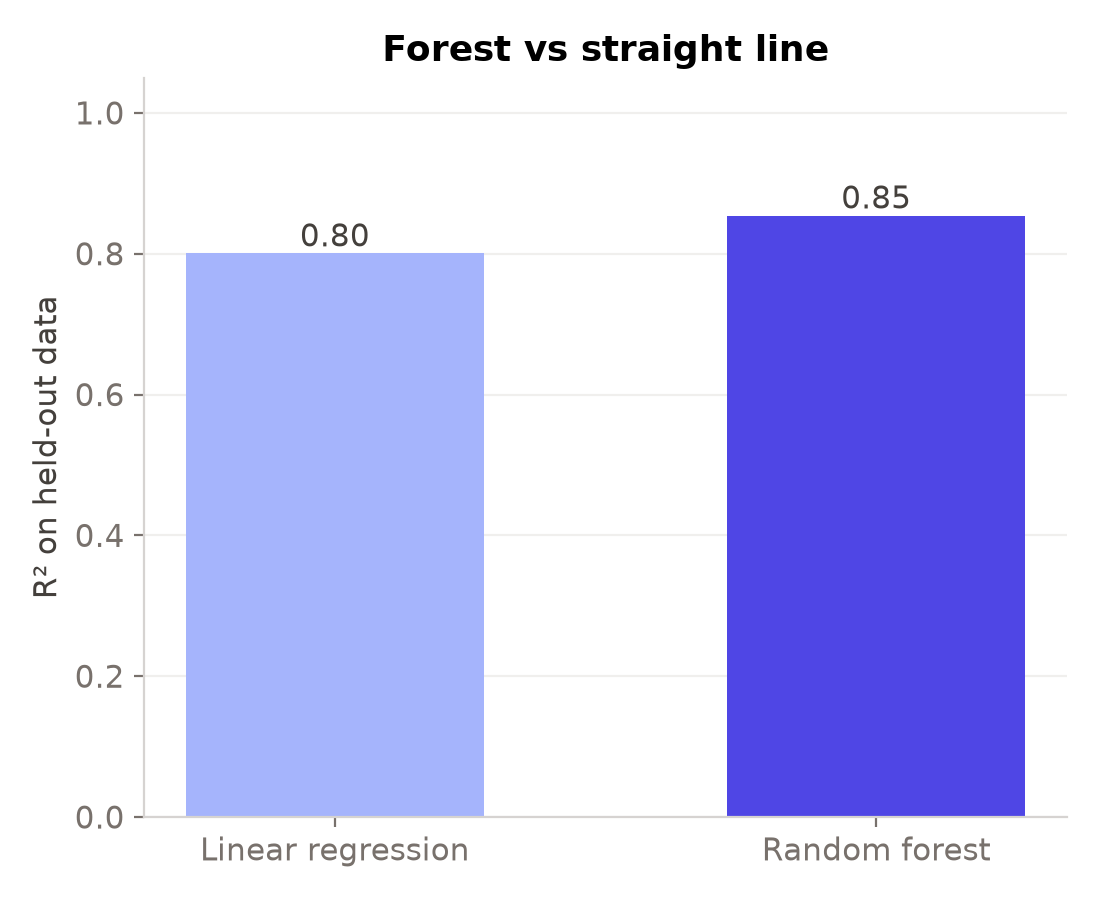

Predicted volatility as beta rises, other inputs held typical. The slope differs by sector.


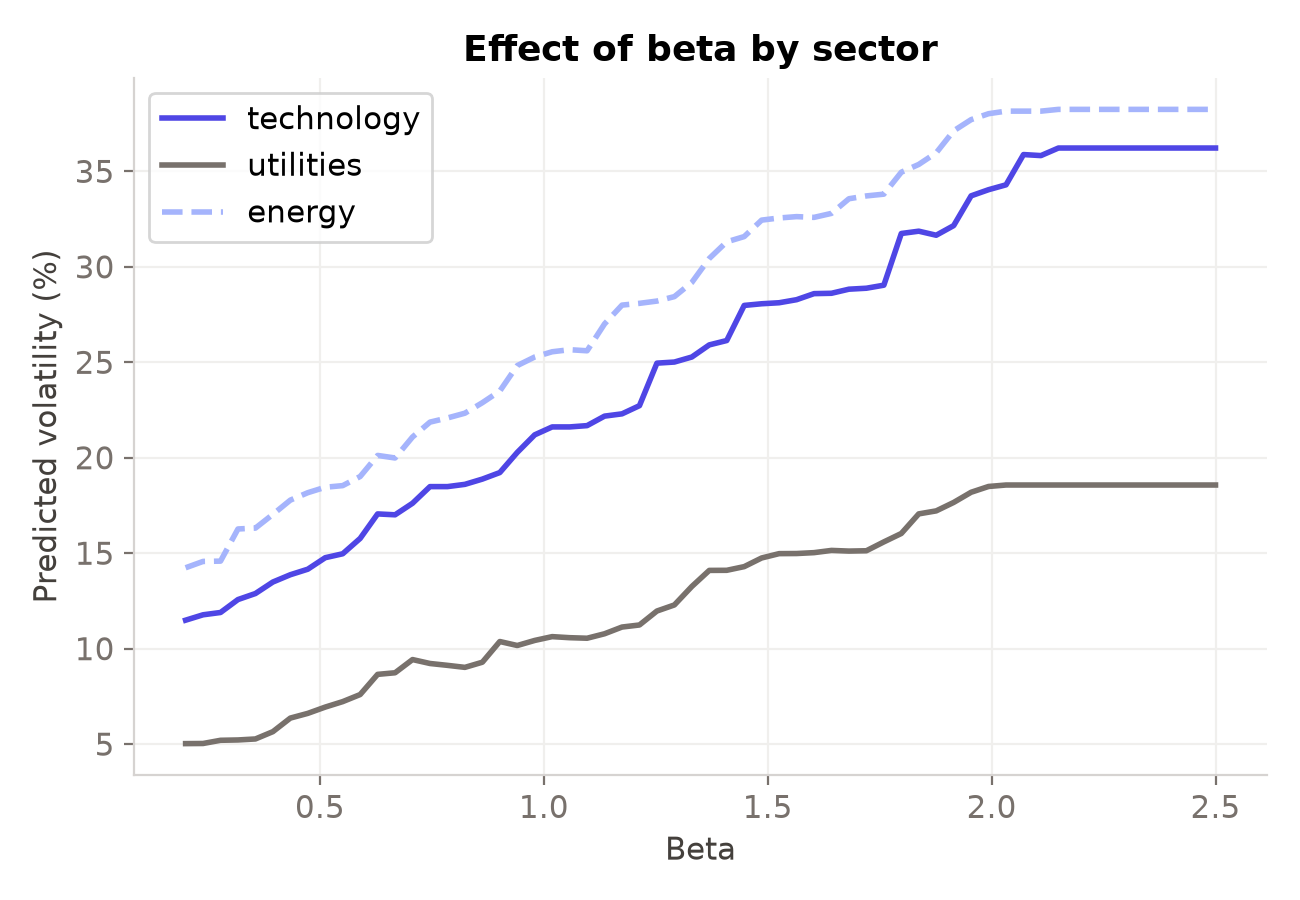

In [5]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## Predict with the exported ONNX model

In [6]:
example = pd.DataFrame([PRESETS[1]["values"]])[ALL_COLUMNS]
print("Volatile small-cap tech ->", f"{onnx_predict(result.model_bytes, example)[0]:.1f}% volatility")

Volatile small-cap tech -> 36.0% volatility


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app. See the README for details.